In [11]:
import seaborn as sea
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

file_path = "../aggregate.csv"
df = pd.read_csv(file_path)

df

,Program,Powercap,IntelCPU.Temperature_C,IntelCPU.Package_J,System.RunningProcesses_processes,Time.WallClock_ms
0,fibonacci-40,-1,58.00,281.078918,3,16094.9316
1,fibonacci-40,-1,57.00,278.588928,1,16053.4112
2,fibonacci-40,-1,56.00,274.955017,2,16060.4114
3,fibonacci-40,-1,57.75,278.289917,2,16068.9883
4,fibonacci-40,-1,57.50,280.057495,3,16037.9243
5,fibonacci-40,-1,58.00,280.832458,3,16120.6305
6,fibonacci-40,-1,56.50,275.431824,1,16041.8678
7,fibonacci-40,-1,56.25,275.076965,1,16037.2106
8,fibonacci-40,-1,57.00,278.730713,1,16033.9711
9,fibonacci-40,-1,56.00,275.118713,1,16045.5224


In [12]:
import pandas as pd

def remove_outliers_package(group):
    Q1 = group['IntelCPU.Package_J'].quantile(0.25)
    Q3 = group['IntelCPU.Package_J'].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return group[(group['IntelCPU.Package_J'] >= lower_bound) & (group['IntelCPU.Package_J'] <= upper_bound)]

df_clean = df.groupby(['Program', 'Powercap']).apply(remove_outliers_package).reset_index(drop=True)
df_clean

/tmp/ipykernel_1224254/4292256757.py:11: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_clean = df.groupby(['Program', 'Powercap']).apply(remove_outliers_package).reset_index(drop=True)


,Program,Powercap,IntelCPU.Temperature_C,IntelCPU.Package_J,System.RunningProcesses_processes,Time.WallClock_ms
0,fibonacci-40,-1,58.00,281.078918,3,16094.9316
1,fibonacci-40,-1,57.00,278.588928,1,16053.4112
2,fibonacci-40,-1,56.00,274.955017,2,16060.4114
3,fibonacci-40,-1,57.75,278.289917,2,16068.9883
4,fibonacci-40,-1,57.50,280.057495,3,16037.9243
5,fibonacci-40,-1,58.00,280.832458,3,16120.6305
6,fibonacci-40,-1,56.50,275.431824,1,16041.8678
7,fibonacci-40,-1,56.25,275.076965,1,16037.2106
8,fibonacci-40,-1,57.00,278.730713,1,16033.9711
9,fibonacci-40,-1,56.00,275.118713,1,16045.5224


In [13]:
# Calculate mean of all numeric columns grouped by Program, and Powercap
df_avg = df_clean.groupby(['Program', 'Powercap']).mean().reset_index()
df_avg

,Program,Powercap,IntelCPU.Temperature_C,IntelCPU.Package_J,System.RunningProcesses_processes,Time.WallClock_ms
0,fibonacci-40,-1,57.000000,277.816095,1.800000,16059.486920
1,fibonacci-40,5,39.583333,138.579868,2.444444,27900.431167


/tmp/ipykernel_1224254/2528238780.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1224254/2528238780.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1224254/2528238780.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1224254/2528238780.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


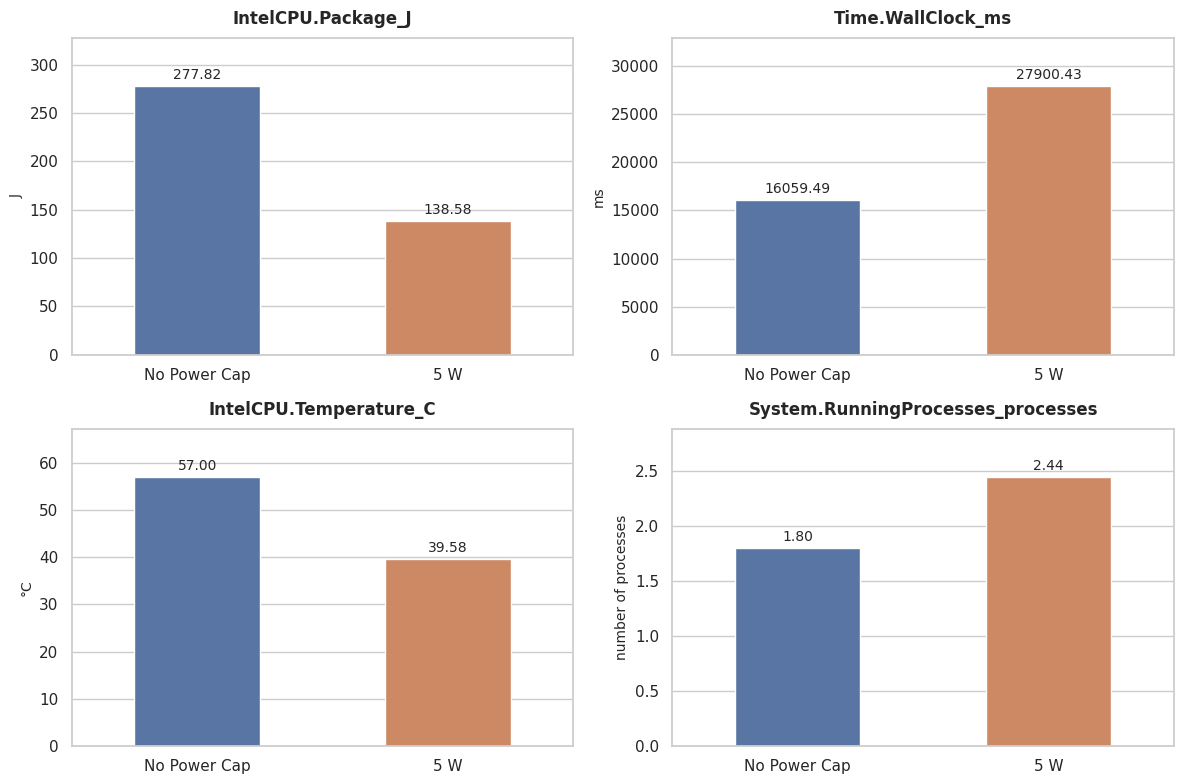

In [14]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


def plot_avg_metrics(df_avg: pd.DataFrame, save_path: str = None):
    sns.set_theme(style="whitegrid")

    df_plot = df_avg.copy()
    df_plot["Powercap_Label"] = df_plot["Powercap"].apply(
        lambda x: "No Power Cap" if x == -1 else f"{x} W"
    )

    metrics = [
        ("IntelCPU.Package_J", "J"),
        ("Time.WallClock_ms", "ms"),
        ("IntelCPU.Temperature_C", "°C"),
        ("System.RunningProcesses_processes", "number of processes"),
    ]

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    axes = axes.flatten()
    palette = ["#4C72B0", "#DD8452"]

    for ax, (col, unit) in zip(axes, metrics):
        sns.barplot(
            data=df_plot,
            x="Powercap_Label",
            y=col,
            palette=palette,
            ax=ax,
            width=0.5,
        )
        ax.set_title(col, fontsize=12, fontweight="bold", pad=10)
        ax.set_xlabel("", fontsize=10)
        ax.set_ylabel(unit, fontsize=10)

        # Add headroom above bars so labels never overlap the top border
        ax.set_ylim(0, df_plot[col].max() * 1.18)

        # Display exact values on top of each bar
        for container in ax.containers:
            ax.bar_label(container, fmt="%.2f", padding=3, fontsize=10)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()


# Example usage:
plot_avg_metrics(df_avg, save_path="aggregate.pdf")